# experiencias treino ldp

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

## Treino com LDP no ciclo cliente–servidor

**Candidata A:** AE+CNN no Icentia11k, MobileNetV2 no PhysioNet, CNN1D global. Mesmos dados, cinco seeds 2031–2035, três rondas, dez épocas locais/ronda e três passos globais/ronda. As 32 âncoras sintéticas são mantidas. Pesos reais de fit 72,73%/27,27%. Sem SA nesta experiência.

,id,mechanism,representation,clip_C
0,P1,gaussiano,original,0.5
1,P2,gaussiano,margem,0.5
2,P3,laplace,margem,2.0


### Condições

Uma referência sem LDP, três controlos só com clipping e três condições com ruído: **7 condições × 5 seeds = 35 avaliações**. As cinco referências compatíveis já concluídas são revalidadas e reutilizadas; os outros 30 treinos são novos. Os controlos com clipping **não são privados**. Nas condições LDP, ε=4 por ciclo de cliente; ε=4/3 por ronda. Gaussianos: δ total=10⁻⁵; Laplace: δ=0. As garantias dos dois mecanismos não são idênticas apenas por terem o mesmo epsilon.

{'status': 'complete', 'validated_conditions': 35, 'reused_baselines': 5, 'signature': 'a26229708ad7e5c0543a63ff78fc32ea976667a1a4e2ff29ee65e17e6e712c63'}

**35/35 avaliações completas e validadas.** Resultados parciais são identificados por `n`; não se escolhe o melhor checkpoint.

{'ldp_condition': 'P1_clipped', 'status': 'running', 'kind': 'Softlabels', 'condition': 'P1_clipped', 'seed': 2035, 'round': 3, 'signature': 'a26229708ad7e5c0543a63ff78fc32ea976667a1a4e2ff29ee65e17e6e712c63'}

{'ldp_condition': 'P1_ldp', 'status': 'running', 'kind': 'Softlabels', 'condition': 'P1_ldp', 'seed': 2035, 'round': 3, 'signature': 'a26229708ad7e5c0543a63ff78fc32ea976667a1a4e2ff29ee65e17e6e712c63'}

{'ldp_condition': 'P2_clipped', 'status': 'running', 'kind': 'Softlabels', 'condition': 'P2_clipped', 'seed': 2035, 'round': 3, 'signature': 'a26229708ad7e5c0543a63ff78fc32ea976667a1a4e2ff29ee65e17e6e712c63'}

{'ldp_condition': 'P2_ldp', 'status': 'running', 'kind': 'Softlabels', 'condition': 'P2_ldp', 'seed': 2035, 'round': 3, 'signature': 'a26229708ad7e5c0543a63ff78fc32ea976667a1a4e2ff29ee65e17e6e712c63'}

{'ldp_condition': 'P3_clipped', 'status': 'running', 'kind': 'Softlabels', 'condition': 'P3_clipped', 'seed': 2035, 'round': 3, 'signature': 'a26229708ad7e5c0543a63ff78fc32ea976667a1a4e2ff29ee65e17e6e712c63'}

{'ldp_condition': 'P3_ldp', 'status': 'running', 'kind': 'Softlabels', 'condition': 'P3_ldp', 'seed': 2035, 'round': 3, 'signature': 'a26229708ad7e5c0543a63ff78fc32ea976667a1a4e2ff29ee65e17e6e712c63'}

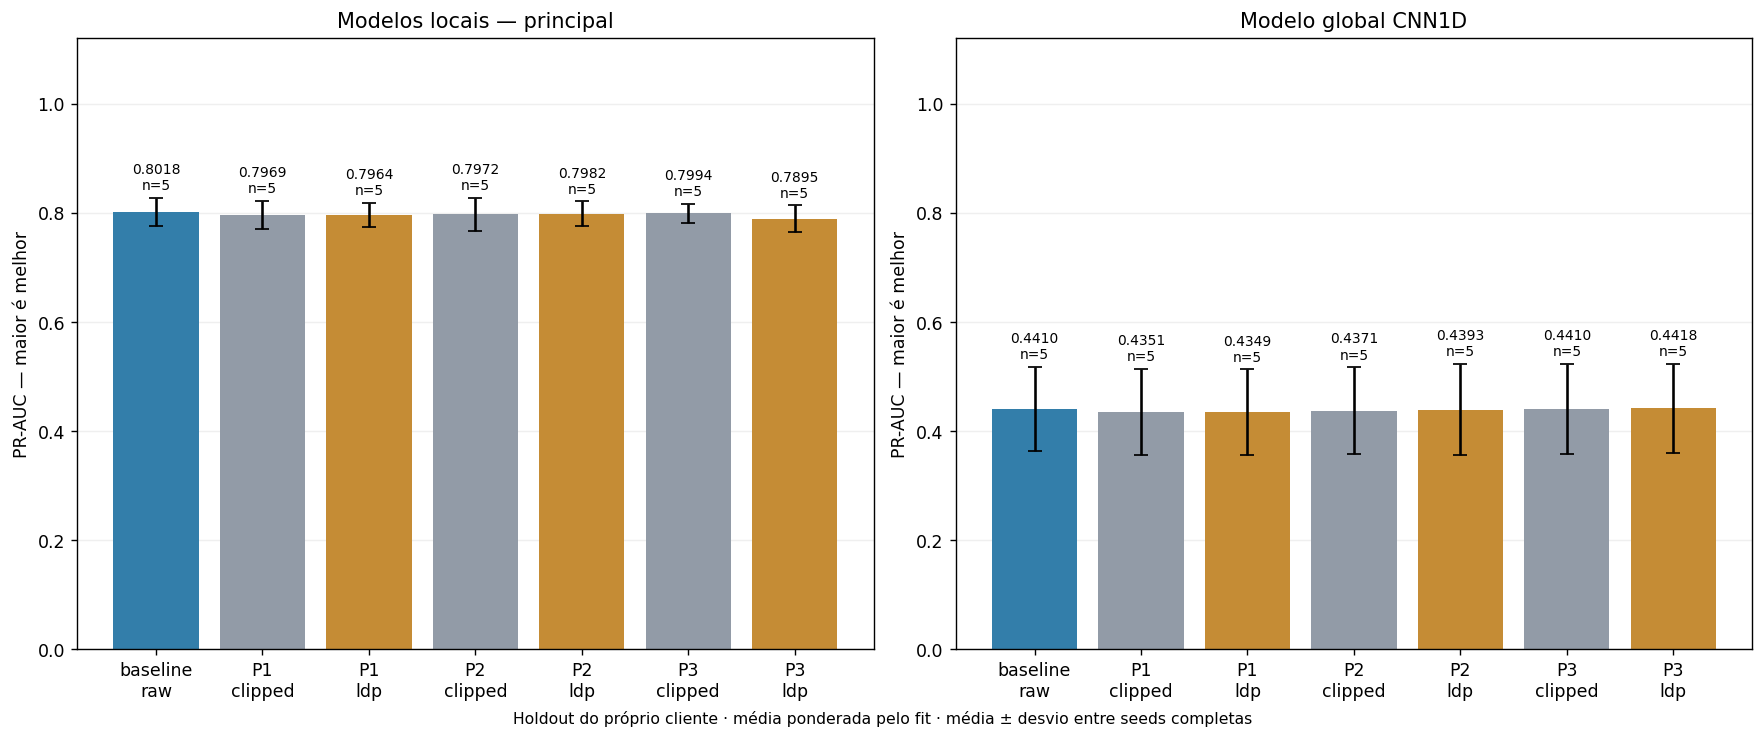

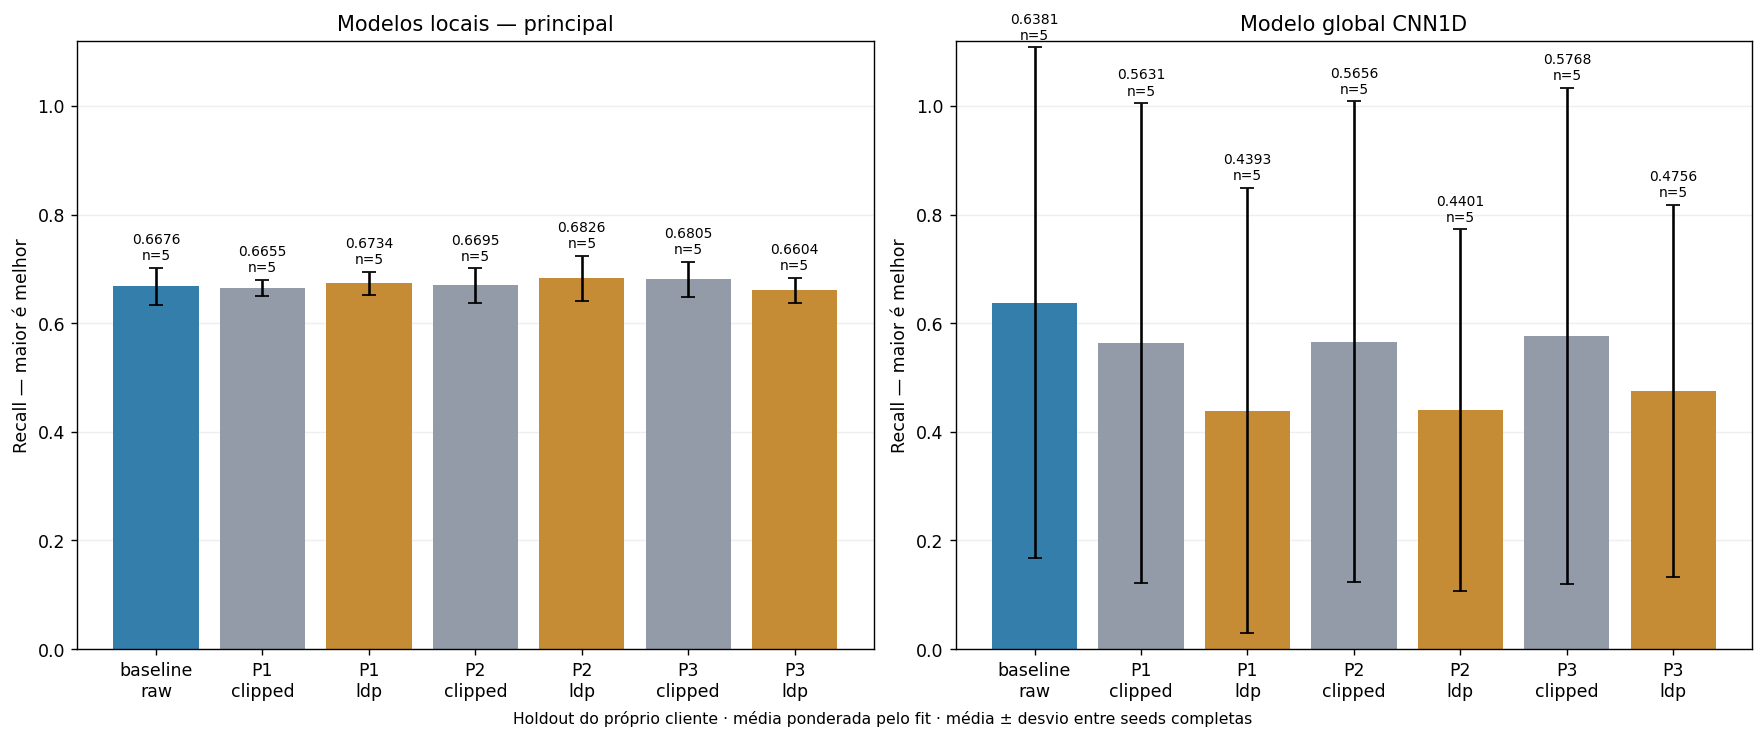

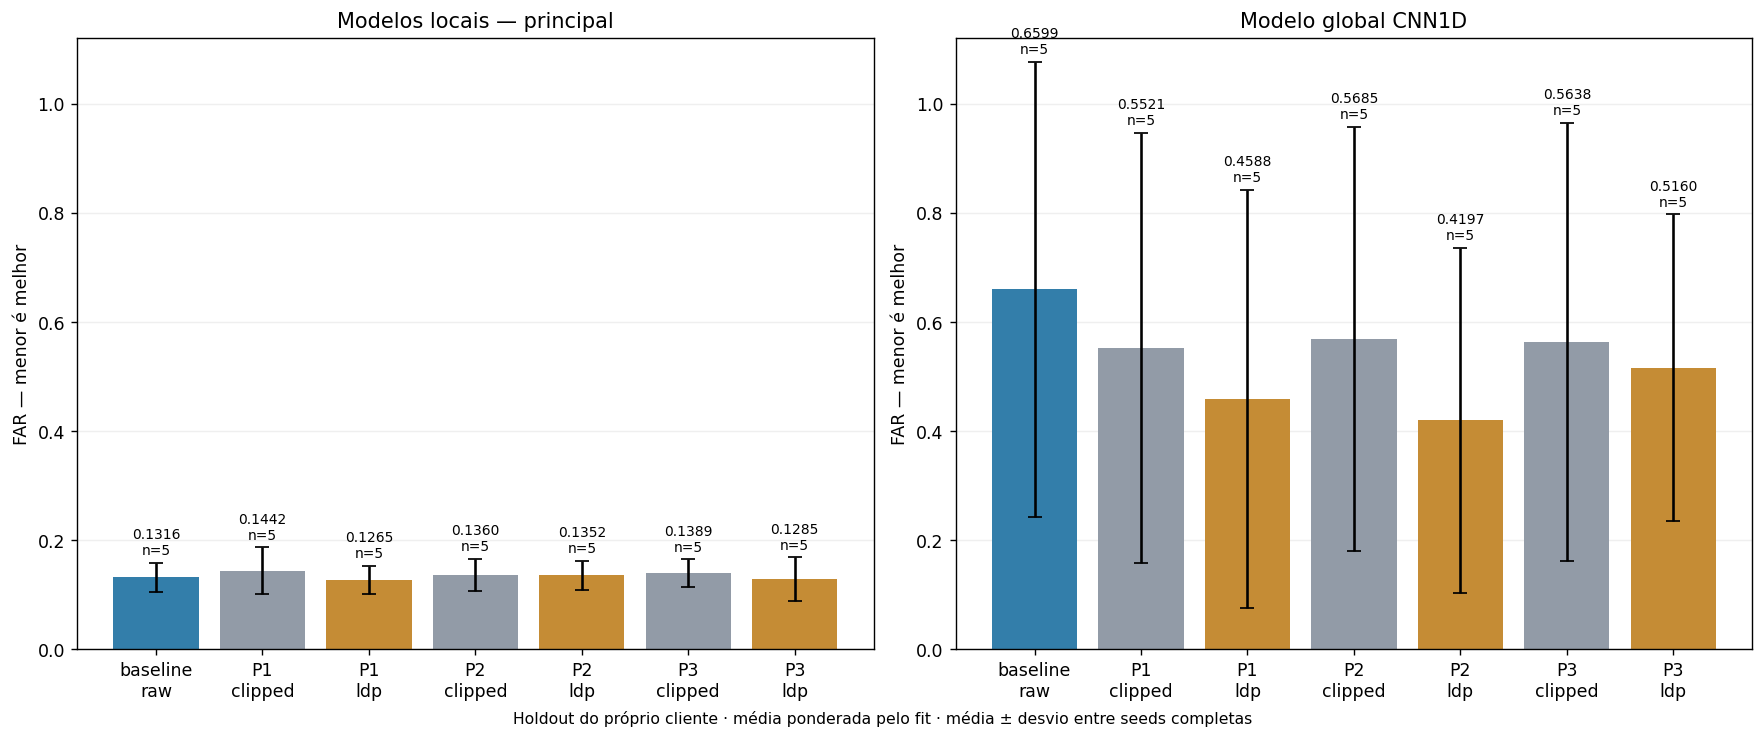

pr_auc_ap                 ...  roc_auc               
                         mean      std count  ...     mean      std count
condition    role                             ...                        
P1_clipped   global   0.43512  0.07869     5  ...  0.48028  0.11544     5
             local    0.79689  0.02570     5  ...  0.84396  0.01877     5
P1_ldp       global   0.43489  0.07815     5  ...  0.48286  0.11531     5
             local    0.79642  0.02166     5  ...  0.84443  0.01426     5
P2_clipped   global   0.43707  0.07989     5  ...  0.48189  0.11587     5
             local    0.79716  0.03046     5  ...  0.84871  0.01996     5
P2_ldp       global   0.43934  0.08420     5  ...  0.48227  0.11917     5
             local    0.79822  0.02266     5  ...  0.85144  0.01586     5
P3_clipped   global   0.44104  0.08234     5  ...  0.48290  0.11644     5
             local    0.79942  0.01729     5  ...  0.84760  0.02044     5
P3_ldp       global   0.44183  0.08187     5  ...  0.48408  0.11316     5
             local    0.78946  0.02421     5  ...  0.84091  0.01534     5
baseline_raw global   0.44101  0.07694     5  ...  0.50171  0.11194     5
             local    0.80183  0.02548     5  ...  0.85224  0.01641     5

[14 rows x 15 columns]

Recall e FAR referem-se à classe anomalia com decisão argmax, sem ajuste ao holdout. AP é a média ponderada dos AP por cliente; não a AP de uma curva de previsões agrupadas. Os resultados dos modelos locais são dos próprios holdouts. O modelo global é avaliado nos mesmos holdouts. Dev é secundário; test reservado.

In [1]:
from support.ldp_logits.notebooks import render_training
render_training()